In [113]:
pip install pandas numpy matplotlib statsmodels openpyxl

In [114]:
import warnings
warnings.filterwarnings("ignore")

import os
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

print("Libraries imported successfully.")

Libraries imported successfully.


In [115]:
import matplotlib.pyplot as plt

In [116]:
df = pd.read_excel("/content/Historical NAV Data.xlsx",sheet_name="Historical NAV Data")

print(df.head())
print(df.columns)

   Net Asset Value       Date
0            19.54 2022-09-01
1            19.58 2022-09-02
2            19.64 2022-09-05
3            19.61 2022-09-06
4            19.63 2022-09-07
Index(['Net Asset Value', 'Date'], dtype='object')


## Data Cleaning

In [117]:
# Display original columns
print("Original columns:")
print(df.columns.tolist())

# Rename columns
df.columns = ["nav", "date"]

# Keep required columns
df = df[["date", "nav"]]

# Convert date
df["date"] = pd.to_datetime(df["date"])

# Convert NAV to numeric
df["nav"] = pd.to_numeric(df["nav"], errors="coerce")

# Remove missing values
df = df.dropna()

# Sort chronologically
df = df.sort_values("date").reset_index(drop=True)

print("Number of observations:", len(df))
print("Start date:", df["date"].min())
print("End date:", df["date"].max())

df.head()

Original columns:
['Net Asset Value', 'Date']
Number of observations: 990
Start date: 2022-09-01 00:00:00
End date: 2026-08-26 00:00:00


,date,nav
0,2022-09-01,19.54
1,2022-09-02,19.58
2,2022-09-05,19.64
3,2022-09-06,19.61
4,2022-09-07,19.63


### Checking missing values

In [118]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
date    0
nav     0
dtype: int64


### Checking duplicate dates

In [119]:
print("Duplicate dates:", df["date"].duplicated().sum())

Duplicate dates: 0


### Checking basic statistics

In [120]:
print(df["nav"].describe())

count    990.000000
mean      25.394586
std        4.288163
min       17.680000
25%       20.942500
50%       26.965000
75%       29.230000
max       32.040000
Name: nav, dtype: float64


### Creating a continuous time series

In [121]:
df = df.set_index("date")

full_range = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="B"
)

ts = df["nav"].reindex(full_range)

print("Total business days:", len(ts))
print("Missing business days:", ts.isna().sum())

# Forward fill missing NAVs
ts = ts.ffill()

ts.index.name = "date"

print(ts.head())
print(ts.tail())

Total business days: 1040
Missing business days: 59
date
2022-09-01    19.54
2022-09-02    19.58
2022-09-05    19.64
2022-09-06    19.61
2022-09-07    19.63
Freq: B, Name: nav, dtype: float64
date
2026-08-20    31.92
2026-08-21    31.97
2026-08-24    31.85
2026-08-25    32.01
2026-08-26    32.03
Freq: B, Name: nav, dtype: float64


### Plotting the NAV Series


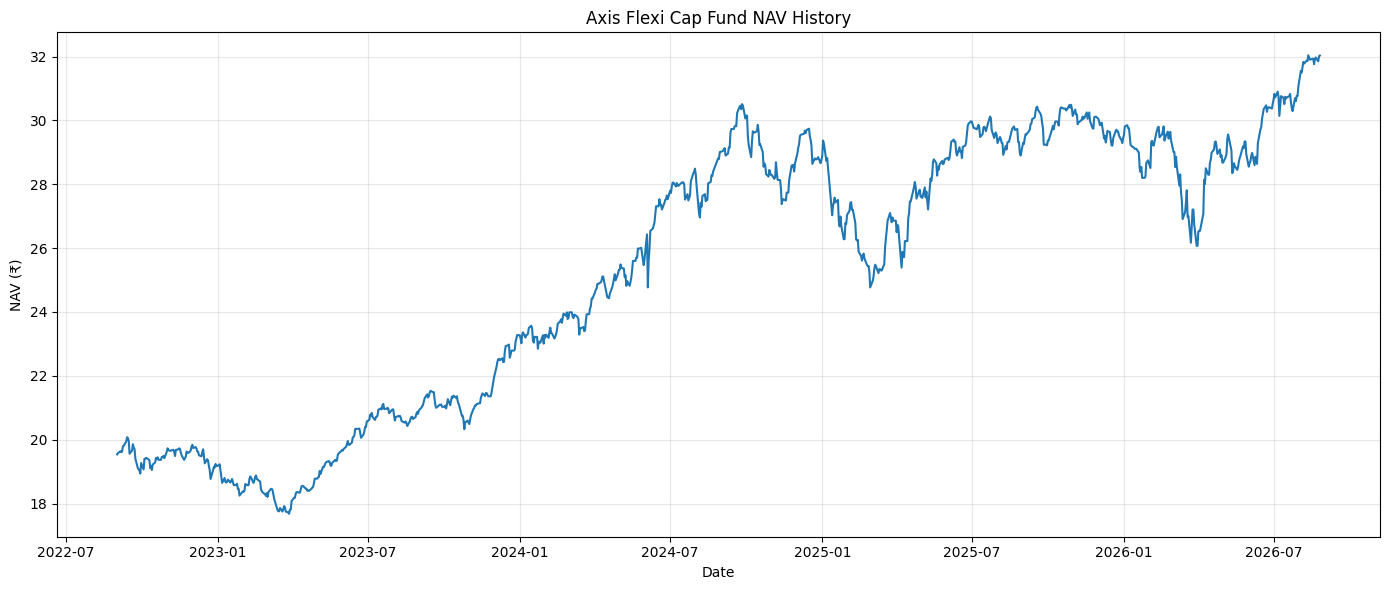

In [122]:
plt.figure(figsize=(14, 6))

plt.plot(ts.index, ts.values)

plt.title("Axis Flexi Cap Fund NAV History")
plt.xlabel("Date")
plt.ylabel("NAV (₹)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

Overall an upward trend could be seen.

### Plotting moving averages

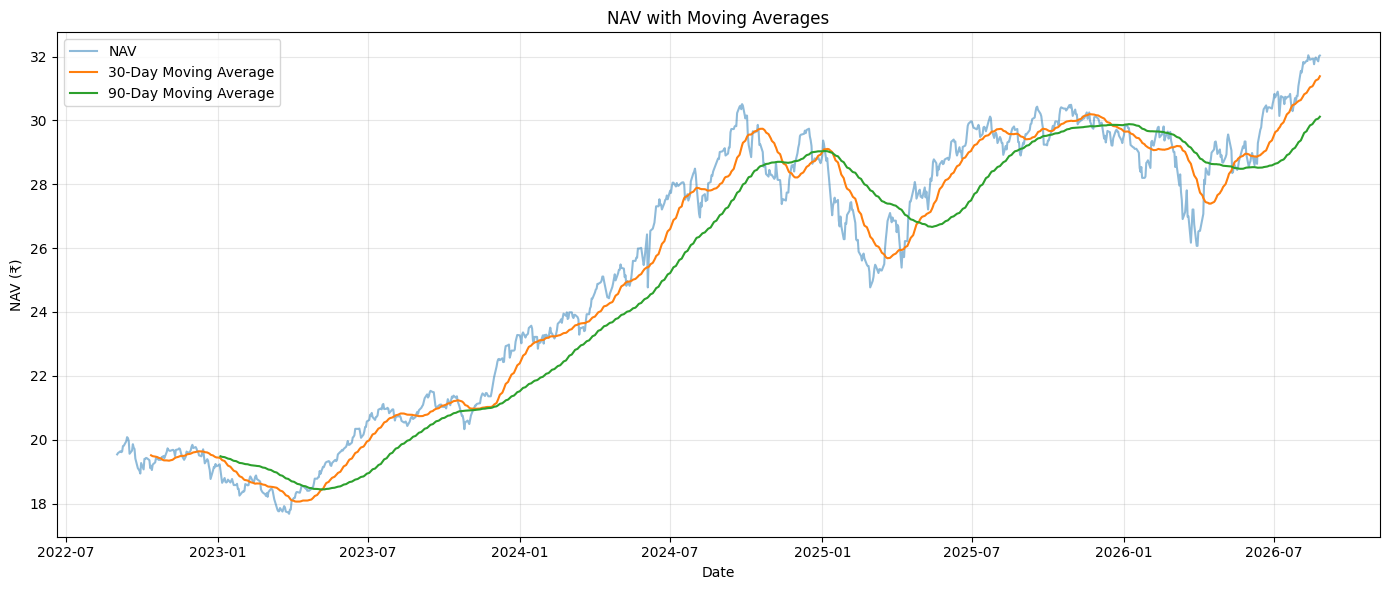

In [123]:
rolling_30 = ts.rolling(window=30).mean()
rolling_90 = ts.rolling(window=90).mean()

plt.figure(figsize=(14, 6))

plt.plot(ts.index, ts.values, label="NAV", alpha=0.5)
plt.plot(rolling_30.index, rolling_30.values, label="30-Day Moving Average")
plt.plot(rolling_90.index, rolling_90.values, label="90-Day Moving Average")

plt.title("NAV with Moving Averages")
plt.xlabel("Date")
plt.ylabel("NAV (₹)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Daily returns

In [124]:
returns = ts.pct_change().dropna()

print(returns.head())
print(returns.describe())

date
2022-09-02    0.002047
2022-09-05    0.003064
2022-09-06   -0.001527
2022-09-07    0.001020
2022-09-08    0.008660
Freq: B, Name: nav, dtype: float64
count    1039.000000
mean        0.000508
std         0.008007
min        -0.062807
25%        -0.003288
50%         0.000689
75%         0.004921
max         0.039527
Name: nav, dtype: float64


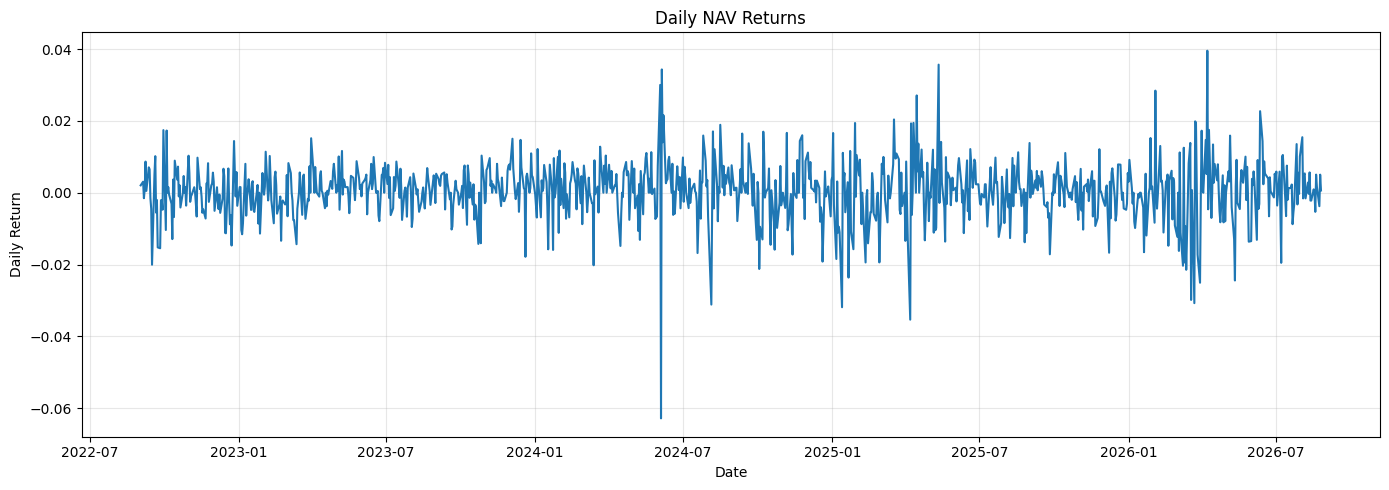

In [125]:
plt.figure(figsize=(14, 5))

plt.plot(returns.index, returns.values)

plt.title("Daily NAV Returns")
plt.xlabel("Date")
plt.ylabel("Daily Return")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### Identifying return outliers

In [126]:
z_scores = (
    returns - returns.mean()
) / returns.std()

outliers = returns[z_scores.abs() > 3]

print("Number of outliers:", len(outliers))

print(outliers)

Number of outliers: 15
date
2024-06-03    0.030008
2024-06-04   -0.062807
2024-06-05    0.034316
2024-08-05   -0.031138
2025-01-13   -0.031877
2025-01-21   -0.023628
2025-04-07   -0.035334
2025-04-15    0.027079
2025-05-12    0.035649
2026-02-03    0.028411
2026-03-19   -0.029845
2026-03-23   -0.030741
2026-03-30   -0.025056
2026-04-08    0.039527
2026-05-12   -0.024432
Name: nav, dtype: float64


### Time series decomposition (Additive Decomposition)

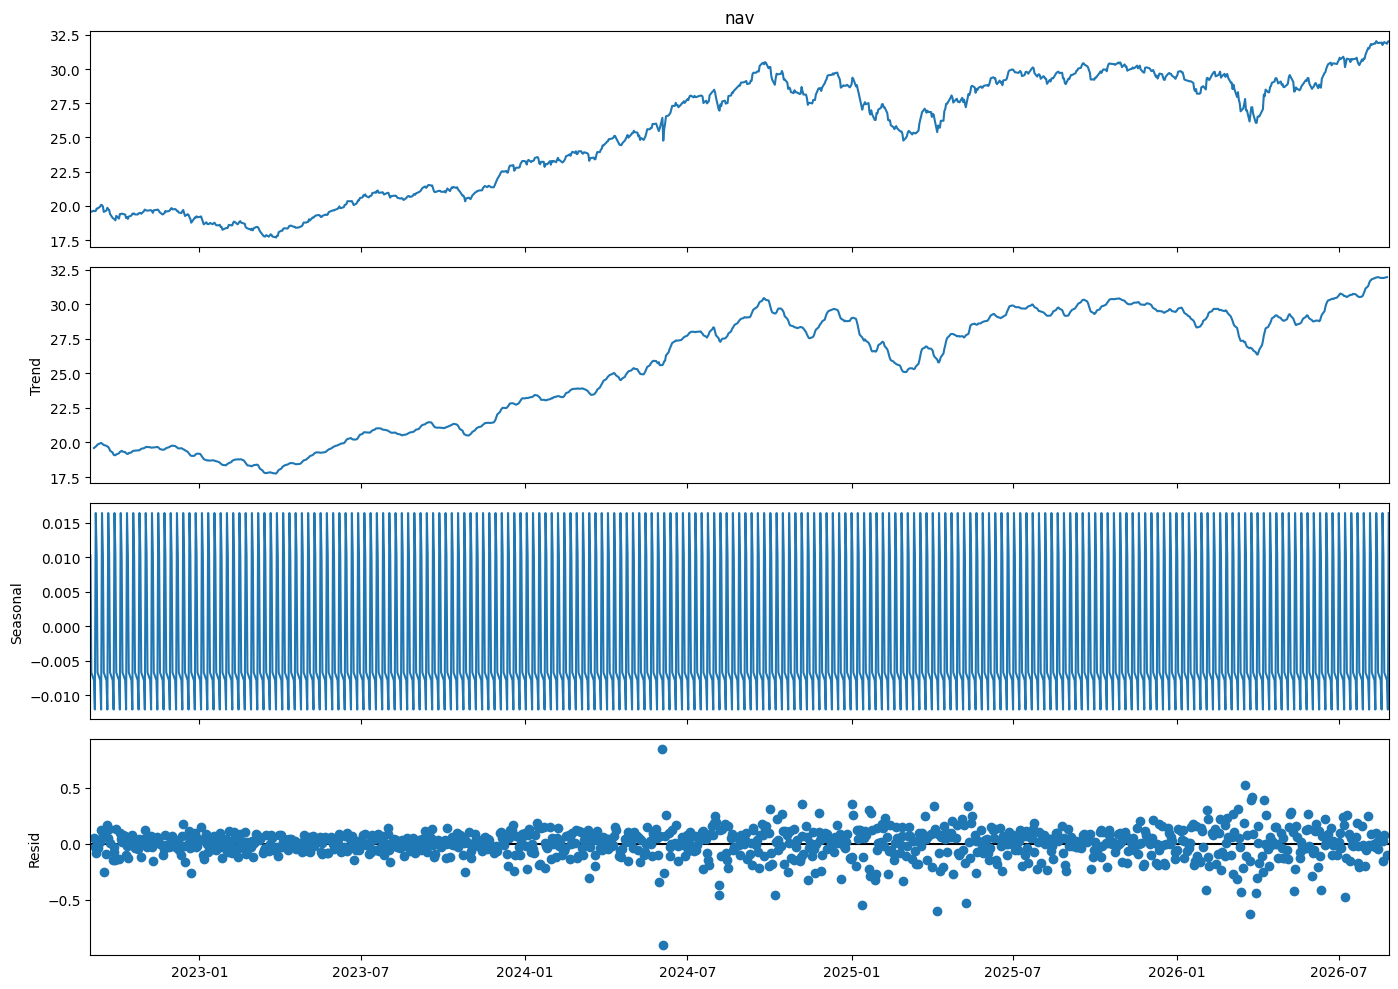

In [127]:
decomp = seasonal_decompose(
    ts,
    model="additive",
    period=5
)

fig = decomp.plot()

fig.set_size_inches(14, 10)

plt.tight_layout()
plt.show()

### Calculating Seasonal Strength

In [128]:
seasonal_strength = (
    decomp.seasonal.std() / ts.std()
)

print(
    f"Seasonal strength: {seasonal_strength:.4f}"
)

if seasonal_strength < 0.05:
    print("Seasonality is weak/negligible.")
else:
    print("Some seasonality is present.")

Seasonal strength: 0.0026
Seasonality is weak/negligible.


### ACF & PACF

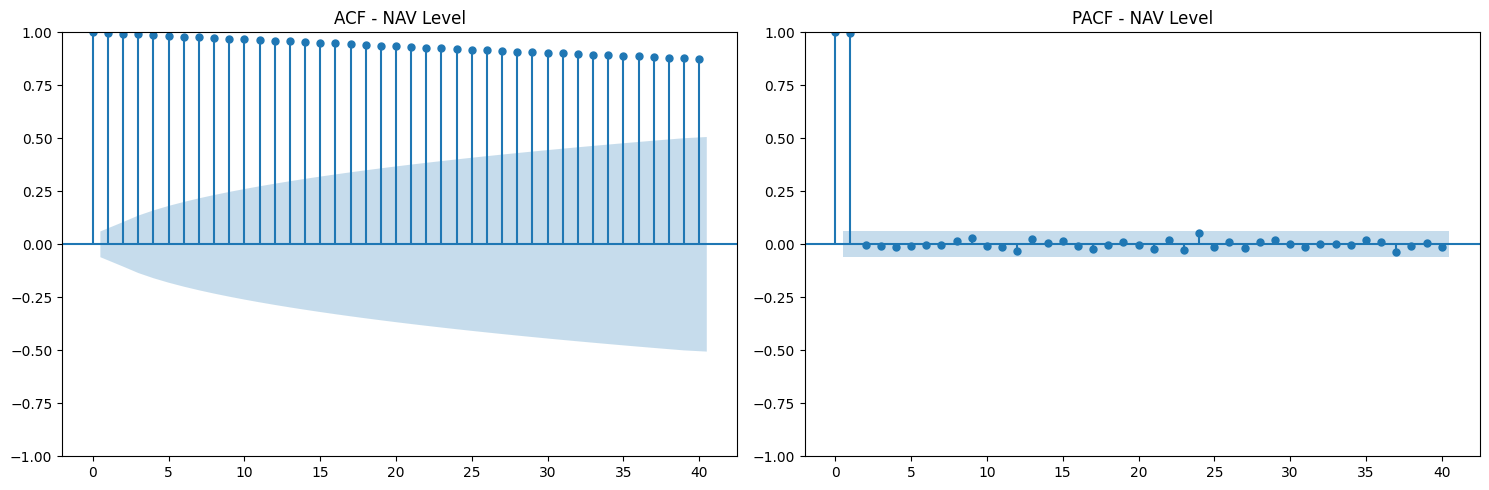

In [129]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

plot_acf(
    ts.dropna(),
    lags=40,
    ax=axes[0]
)

plot_pacf(
    ts.dropna(),
    lags=40,
    ax=axes[1],
    method="ywm"
)

axes[0].set_title("ACF - NAV Level")
axes[1].set_title("PACF - NAV Level")

plt.tight_layout()
plt.show()

### ADF stationarity test

In [130]:
def adf_test(series, name):

    result = adfuller(series.dropna())

    print("=" * 50)
    print("ADF Test:", name)
    print("=" * 50)

    print("ADF Statistic:", round(result[0], 4))
    print("p-value:", round(result[1], 4))

    if result[1] < 0.05:
        print("Conclusion: Stationary")
    else:
        print("Conclusion: Non-stationary")

    return result

In [131]:
adf_level = adf_test(
    ts,
    "NAV Level"
)

ADF Test: NAV Level
ADF Statistic: -0.602
p-value: 0.8705
Conclusion: Non-stationary


### Log Transformation

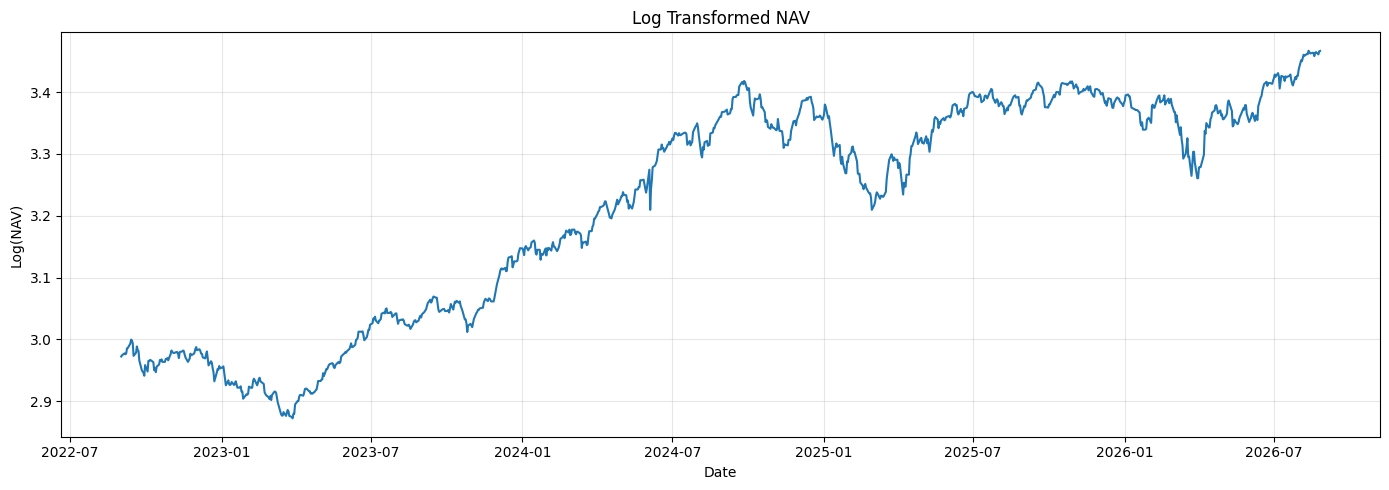

In [132]:
log_ts = np.log(ts)

plt.figure(figsize=(14, 5))

plt.plot(log_ts)

plt.title("Log Transformed NAV")
plt.xlabel("Date")
plt.ylabel("Log(NAV)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### First diffrencing

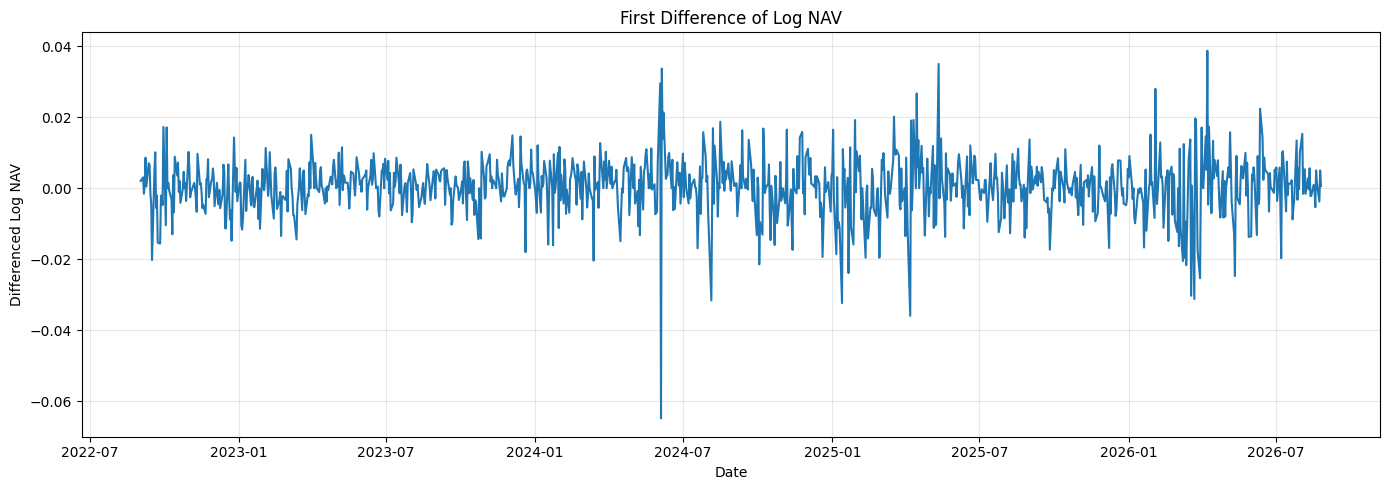

In [133]:
diff_log_ts = log_ts.diff().dropna()

plt.figure(figsize=(14, 5))

plt.plot(diff_log_ts)

plt.title("First Difference of Log NAV")
plt.xlabel("Date")
plt.ylabel("Differenced Log NAV")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

### ADF test after differencing

In [134]:
adf_diff = adf_test(
    diff_log_ts,
    "First Difference of Log NAV"
)

ADF Test: First Difference of Log NAV
ADF Statistic: -21.5701
p-value: 0.0
Conclusion: Stationary


### ACF/PACF of stationary series

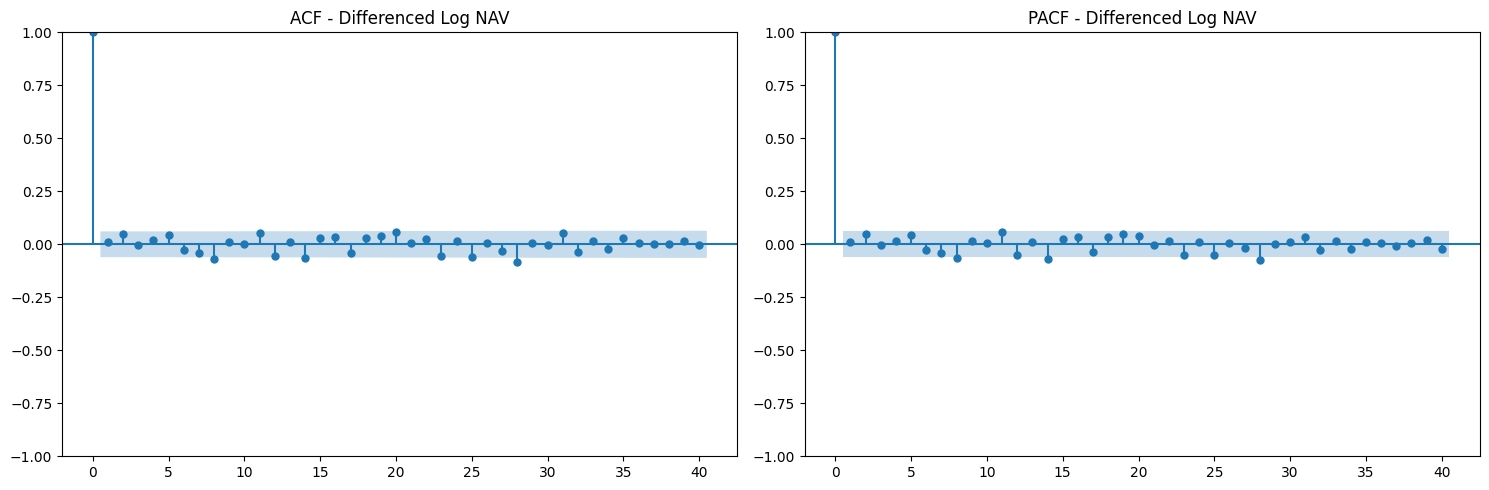

In [135]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 5)
)

plot_acf(
    diff_log_ts,
    lags=40,
    ax=axes[0]
)

plot_pacf(
    diff_log_ts,
    lags=40,
    ax=axes[1],
    method="ywm"
)

axes[0].set_title("ACF - Differenced Log NAV")
axes[1].set_title("PACF - Differenced Log NAV")

plt.tight_layout()
plt.show()

### Train-test split

In [136]:
TEST_SIZE = 90

train = ts.iloc[:-TEST_SIZE]
test = ts.iloc[-TEST_SIZE:]

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train.index.min(), "to", train.index.max())

print("\nTesting period:")
print(test.index.min(), "to", test.index.max())

Training observations: 950
Testing observations: 90

Training period:
2022-09-01 00:00:00 to 2026-04-22 00:00:00

Testing period:
2026-04-23 00:00:00 to 2026-08-26 00:00:00


## Naive Model

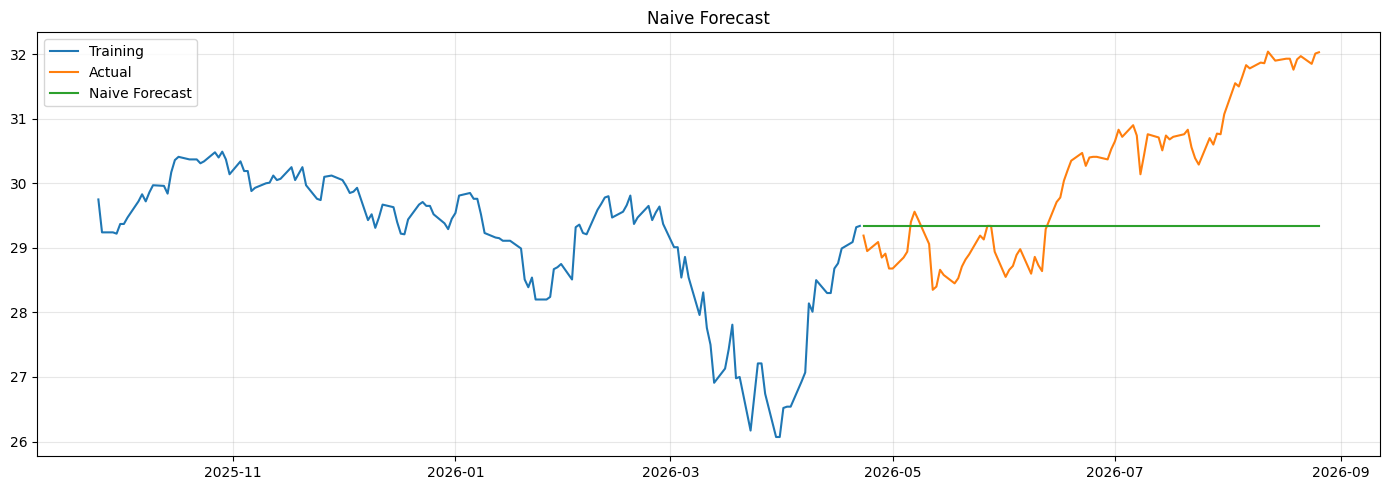

In [137]:
naive_forecast = pd.Series(
    train.iloc[-1],
    index=test.index
)

plt.figure(figsize=(14, 5))

plt.plot(train.index[-150:], train.iloc[-150:], label="Training")
plt.plot(test.index, test, label="Actual")
plt.plot(test.index, naive_forecast, label="Naive Forecast")

plt.title("Naive Forecast")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Moving Average Method

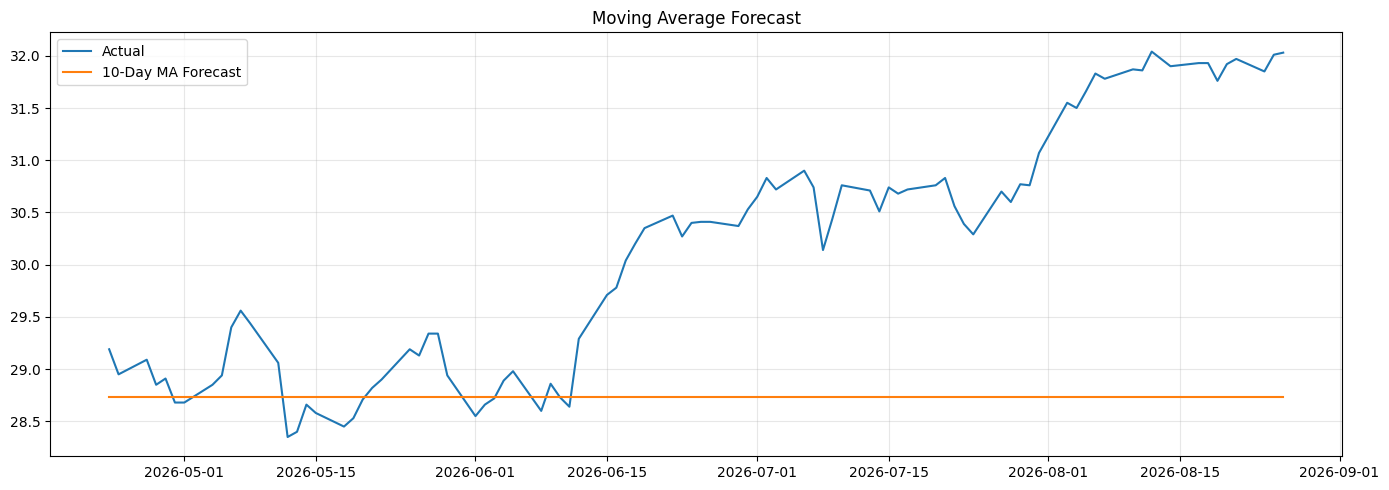

In [138]:
MA_WINDOW = 10

ma_value = train.iloc[-MA_WINDOW:].mean()

ma_forecast = pd.Series(
    ma_value,
    index=test.index
)

plt.figure(figsize=(14, 5))

plt.plot(test.index, test, label="Actual")
plt.plot(test.index, ma_forecast, label="10-Day MA Forecast")

plt.title("Moving Average Forecast")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Holt Exponential Smoothing (Tripple Exponential Smoothing)

In [139]:
holt_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal=None,
    initialization_method="estimated"
)

holt_fit = holt_model.fit()

holt_forecast = holt_fit.forecast(TEST_SIZE)

holt_forecast.index = test.index

print(holt_forecast.head())

date
2026-04-23    29.350327
2026-04-24    29.360653
2026-04-27    29.370980
2026-04-28    29.381307
2026-04-29    29.391633
Freq: B, dtype: float64


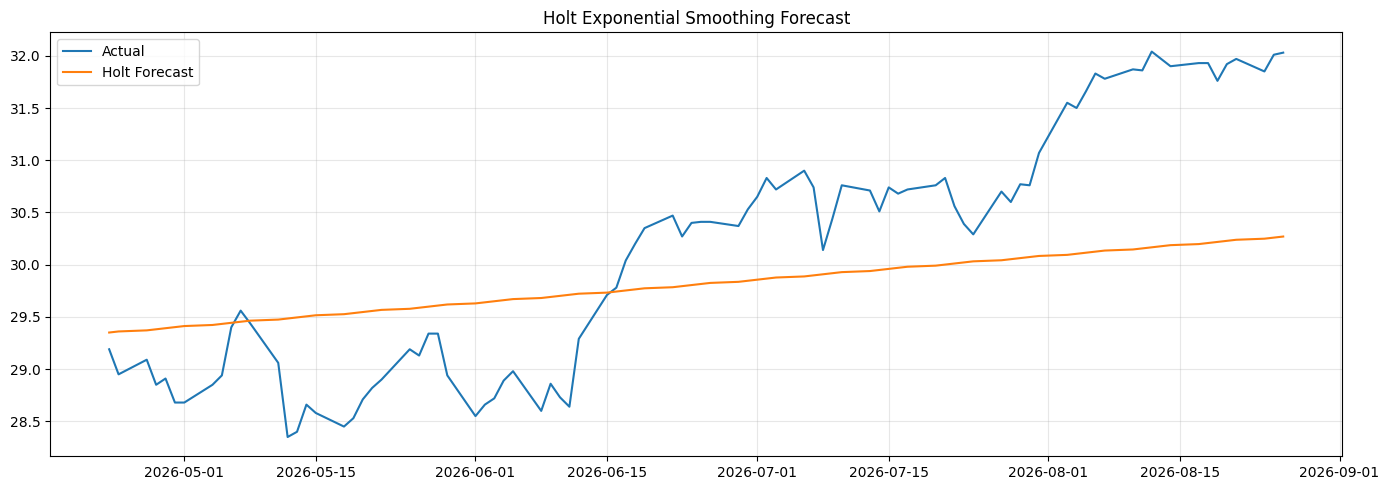

In [140]:
plt.figure(figsize=(14, 5))

plt.plot(test.index, test, label="Actual")
plt.plot(test.index, holt_forecast, label="Holt Forecast")

plt.title("Holt Exponential Smoothing Forecast")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## ARIMA


In [141]:
log_train = np.log(train)

In [142]:
def find_best_arima(
    series,
    p_values=range(0, 4),
    d_values=[1],
    q_values=range(0, 4)
):

    best_aic = np.inf
    best_order = None
    best_model = None

    for p, d, q in itertools.product(
        p_values,
        d_values,
        q_values
    ):

        try:

            model = SARIMAX(
                series,
                order=(p, d, q),
                seasonal_order=(0, 0, 0, 0),
                enforce_stationarity=False,
                enforce_invertibility=False
            )

            fitted = model.fit(
                disp=False
            )

            if fitted.aic < best_aic:

                best_aic = fitted.aic
                best_order = (p, d, q)
                best_model = fitted

        except Exception:
            continue

    return best_order, best_aic, best_model

In [143]:
best_arima_order, best_arima_aic, arima_model = find_best_arima(
    log_train
)

print("Best ARIMA order:", best_arima_order)
print("Best AIC:", best_arima_aic)

Best ARIMA order: (0, 1, 0)
Best AIC: -6442.036152394026


## ARIMA forecast

In [144]:
log_arima_forecast = arima_model.get_forecast(
    steps=TEST_SIZE
)

log_arima_mean = (
    log_arima_forecast.predicted_mean
)

arima_forecast = np.exp(
    log_arima_mean
)

arima_forecast.index = test.index

print(arima_forecast.head())

date
2026-04-23    29.34
2026-04-24    29.34
2026-04-27    29.34
2026-04-28    29.34
2026-04-29    29.34
Freq: B, Name: predicted_mean, dtype: float64


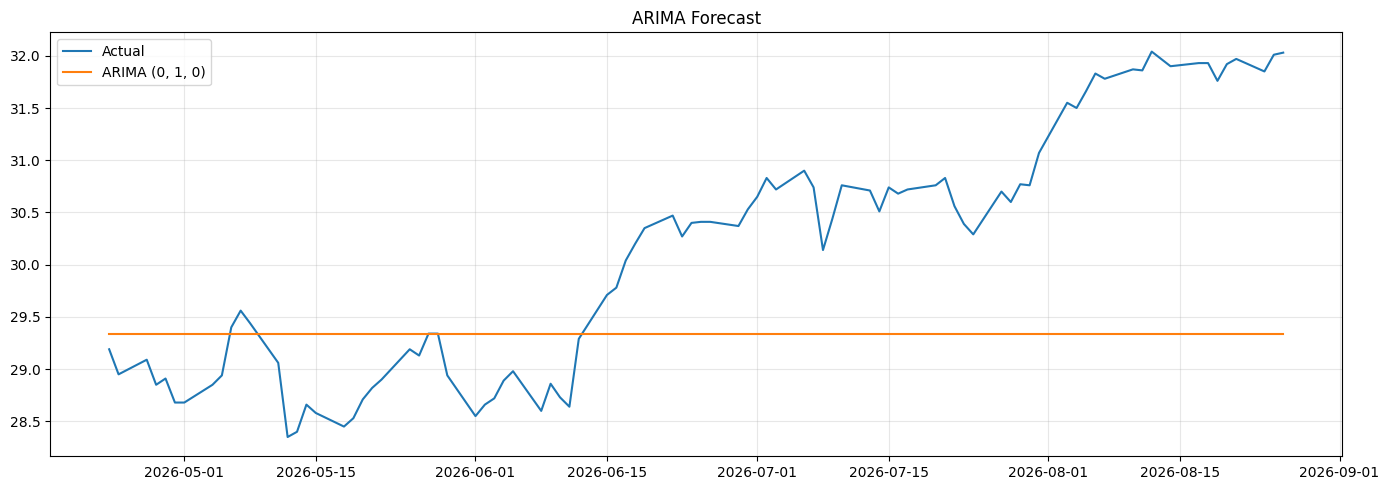

In [145]:
plt.figure(figsize=(14, 5))

plt.plot(test.index, test, label="Actual")
plt.plot(
    test.index,
    arima_forecast,
    label=f"ARIMA {best_arima_order}"
)

plt.title("ARIMA Forecast")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### SARIMA

In [148]:
def find_best_sarima(
    series,
    p_values=range(0, 3),
    d_values=[1],
    q_values=range(0, 3),
    P_values=range(0, 2),
    D_values=[0, 1],
    Q_values=range(0, 2),
    seasonal_period=5
):

    best_aic = np.inf
    best_order = None
    best_seasonal_order = None
    best_model = None

    for p, d, q in itertools.product(
        p_values,
        d_values,
        q_values
    ):

        for P, D, Q in itertools.product(
            P_values,
            D_values,
            Q_values
        ):

            try:

                model = SARIMAX(
                    series,
                    order=(p, d, q),
                    seasonal_order=(
                        P,
                        D,
                        Q,
                        seasonal_period
                    ),
                    enforce_stationarity=False,
                    enforce_invertibility=False
                )

                fitted = model.fit(
                    disp=False
                )

                if fitted.aic < best_aic:

                    best_aic = fitted.aic
                    best_order = (p, d, q)
                    best_seasonal_order = (
                        P, D, Q, seasonal_period
                    )
                    best_model = fitted

            except Exception:
                continue

    return (
        best_order,
        best_seasonal_order,
        best_aic,
        best_model
    )

In [149]:
(
    best_sarima_order,
    best_sarima_seasonal_order,
    best_sarima_aic,
    sarima_model
) = find_best_sarima(
    log_train
)

print(
    "Best SARIMA order:",
    best_sarima_order
)

print(
    "Best seasonal order:",
    best_sarima_seasonal_order
)

print(
    "Best AIC:",
    best_sarima_aic
)

Best SARIMA order: (0, 1, 0)
Best seasonal order: (0, 0, 0, 5)
Best AIC: -6442.036152394026


## SARIMA Forecast

In [150]:
log_sarima_result = sarima_model.get_forecast(
    steps=TEST_SIZE
)

log_sarima_mean = (
    log_sarima_result.predicted_mean
)

sarima_forecast = np.exp(
    log_sarima_mean
)

sarima_forecast.index = test.index

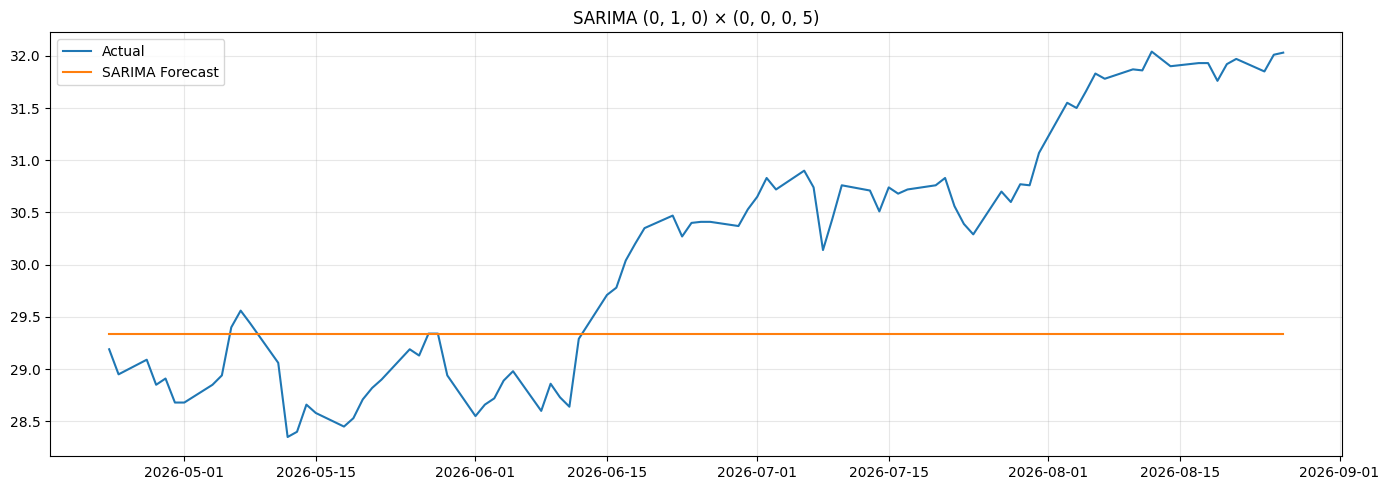

In [151]:
plt.figure(figsize=(14, 5))

plt.plot(
    test.index,
    test,
    label="Actual"
)

plt.plot(
    test.index,
    sarima_forecast,
    label="SARIMA Forecast"
)

plt.title(
    f"SARIMA {best_sarima_order} × "
    f"{best_sarima_seasonal_order}"
)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## SARIMAX

In [152]:
def dow_dummies(index):

    dow = pd.get_dummies(
        index.day_name(),
        prefix="dow"
    )

    dow.index = index

    required_columns = [
        "dow_Monday",
        "dow_Tuesday",
        "dow_Wednesday",
        "dow_Thursday",
        "dow_Friday"
    ]

    for col in required_columns:

        if col not in dow.columns:
            dow[col] = 0

    # Drop Monday as reference category
    dow = dow[
        [
            "dow_Tuesday",
            "dow_Wednesday",
            "dow_Thursday",
            "dow_Friday"
        ]
    ]

    return dow.astype(float)

In [153]:
# train test split
exog_train = dow_dummies(train.index)

exog_test = dow_dummies(test.index)

print(exog_train.head())

            dow_Tuesday  dow_Wednesday  dow_Thursday  dow_Friday
date                                                            
2022-09-01          0.0            0.0           1.0         0.0
2022-09-02          0.0            0.0           0.0         1.0
2022-09-05          0.0            0.0           0.0         0.0
2022-09-06          1.0            0.0           0.0         0.0
2022-09-07          0.0            1.0           0.0         0.0


In [154]:
sarimax_model = SARIMAX(
    log_train,
    order=best_arima_order,
    seasonal_order=(0, 0, 0, 0),
    exog=exog_train,
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_fit = sarimax_model.fit(
    disp=False
)

print(sarimax_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                    nav   No. Observations:                  950
Model:               SARIMAX(0, 1, 0)   Log Likelihood                3224.257
Date:                Sun, 30 Aug 2026   AIC                          -6438.515
Time:                        19:32:21   BIC                          -6414.243
Sample:                    09-01-2022   HQIC                         -6429.266
                         - 04-22-2026                                         
Covariance Type:                  opg                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
dow_Tuesday       0.0002      0.001      0.317      0.751      -0.001       0.001
dow_Wednesday     0.0011      0.001      1.729      0.084      -0.000       0.002
dow_Thursday      0.0008      0.001     

## SARIMAX Forecast

In [155]:
sarimax_result = sarimax_fit.get_forecast(
    steps=TEST_SIZE,
    exog=exog_test
)

log_sarimax_forecast = (
    sarimax_result.predicted_mean
)

sarimax_forecast = np.exp(
    log_sarimax_forecast
)

sarimax_forecast.index = test.index

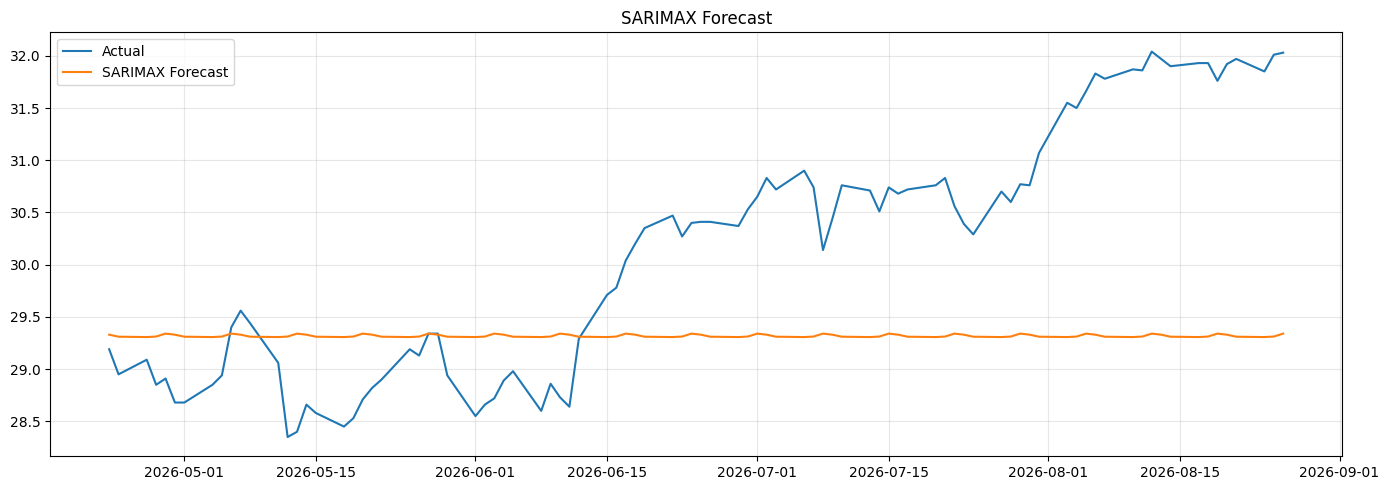

In [156]:
plt.figure(figsize=(14, 5))

plt.plot(
    test.index,
    test,
    label="Actual"
)

plt.plot(
    test.index,
    sarimax_forecast,
    label="SARIMAX Forecast"
)

plt.title("SARIMAX Forecast")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [157]:
forecasts = {}

forecasts["Naive"] = naive_forecast
forecasts["Moving Average"] = ma_forecast
forecasts["Holt"] = holt_forecast
forecasts["ARIMA"] = arima_forecast
forecasts["SARIMA"] = sarima_forecast
forecasts["SARIMAX"] = sarimax_forecast

In [158]:
for name, forecast in forecasts.items():

    print(
        name,
        "→",
        len(forecast),
        "forecast observations"
    )

Naive → 90 forecast observations
Moving Average → 90 forecast observations
Holt → 90 forecast observations
ARIMA → 90 forecast observations
SARIMA → 90 forecast observations
SARIMAX → 90 forecast observations


## Evaluating Models

In [159]:
def MAE(actual, predicted):

    return np.mean(
        np.abs(actual - predicted)
    )


def RMSE(actual, predicted):

    return np.sqrt(
        np.mean(
            (actual - predicted) ** 2
        )
    )


def MAPE(actual, predicted):

    return np.mean(
        np.abs(
            (actual - predicted) / actual
        )
    ) * 100

In [160]:
results = []

for name, forecast in forecasts.items():

    results.append({
        "Model": name,
        "MAE": MAE(
            test.values,
            forecast.values
        ),
        "RMSE": RMSE(
            test.values,
            forecast.values
        ),
        "MAPE (%)": MAPE(
            test.values,
            forecast.values
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "RMSE"
).reset_index(drop=True)

results_df

,Model,MAE,RMSE,MAPE (%)
0,Holt,0.841769,0.974103,2.763568
1,Naive,1.155889,1.402012,3.754310
2,ARIMA,1.155889,1.402012,3.754310
3,SARIMA,1.155889,1.402012,3.754310
4,SARIMAX,1.160619,1.413318,3.767823
5,Moving Average,1.431244,1.813035,4.617850


## Model Comparision

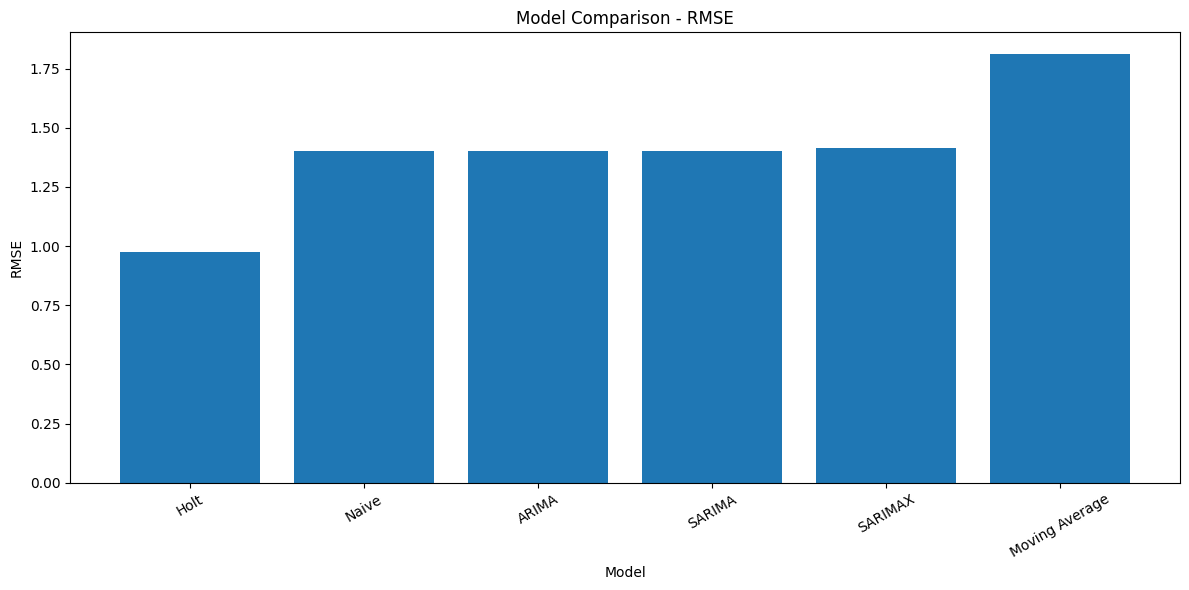

In [161]:
plt.figure(figsize=(12, 6))

plt.bar(
    results_df["Model"],
    results_df["RMSE"]
)

plt.title("Model Comparison - RMSE")
plt.xlabel("Model")
plt.ylabel("RMSE")

plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

## Comparing Actual vs All Models

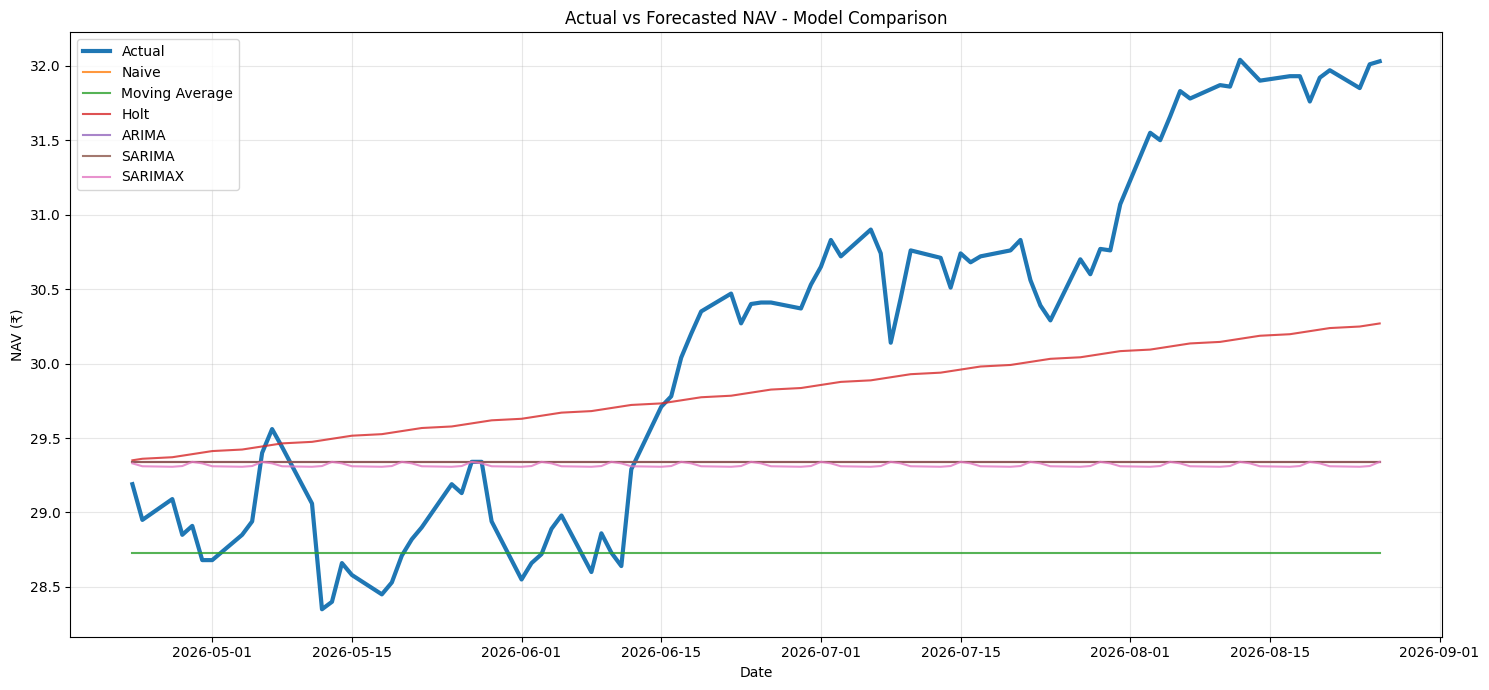

In [162]:
plt.figure(figsize=(15, 7))

plt.plot(
    test.index,
    test.values,
    label="Actual",
    linewidth=3
)

for name, forecast in forecasts.items():

    plt.plot(
        test.index,
        forecast.values,
        label=name,
        alpha=0.8
    )

plt.title(
    "Actual vs Forecasted NAV - Model Comparison"
)

plt.xlabel("Date")
plt.ylabel("NAV (₹)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Selecting the best model

In [163]:
best_model_name = results_df.iloc[0]["Model"]

print(
    "Best model based on RMSE:",
    best_model_name
)

Best model based on RMSE: Holt


In [164]:
best_mape_model = (
    results_df
    .sort_values("MAPE (%)")
    .iloc[0]["Model"]
)

print(
    "Best model based on MAPE:",
    best_mape_model
)

Best model based on MAPE: Holt


## AIC

In [165]:
def calculate_aicc(model):

    aic = model.aic
    n = model.nobs
    k = model.df_model

    aicc = aic + (
        2 * k * (k + 1)
    ) / (n - k - 1)

    return aic, aicc

In [166]:
models_for_aic = {
    "ARIMA": arima_model,
    "SARIMA": sarima_model,
    "SARIMAX": sarimax_fit
}

aic_results = []

for name, model in models_for_aic.items():

    aic, aicc = calculate_aicc(model)

    aic_results.append({
        "Model": name,
        "AIC": aic,
        "AICc": aicc
    })

aic_df = pd.DataFrame(aic_results)

aic_df

,Model,AIC,AICc
0,ARIMA,-6442.036152,-6442.031933
1,SARIMA,-6442.036152,-6442.031933
2,SARIMAX,-6438.514961,-6438.451402


## Residual Diagnostic

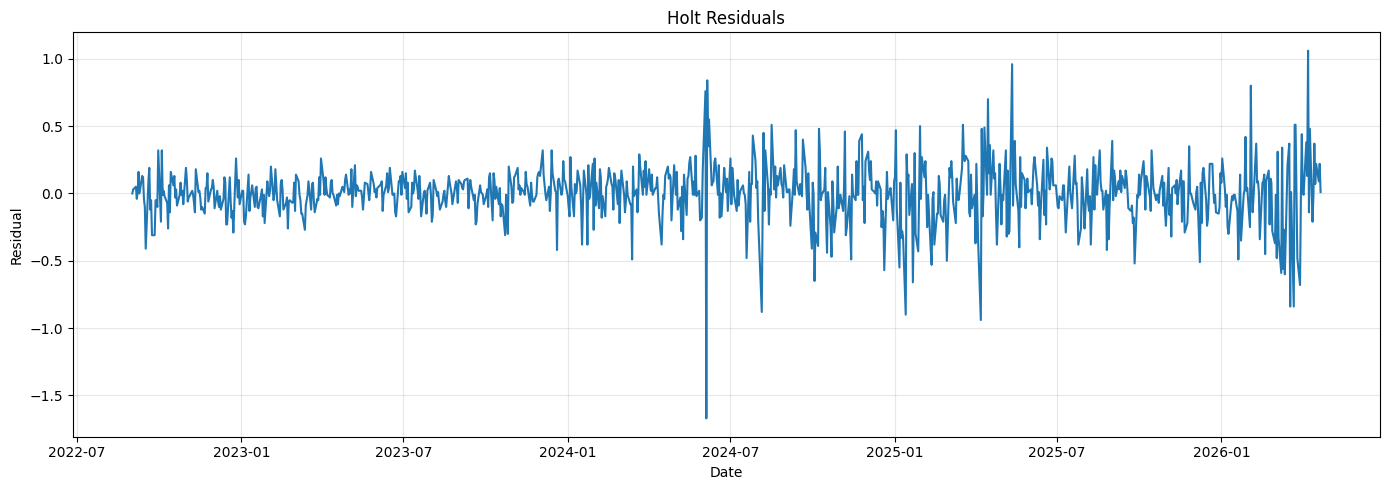

In [169]:
residuals = holt_fit.resid

plt.figure(figsize=(14, 5))

plt.plot(residuals)

plt.title("Holt Residuals")
plt.xlabel("Date")
plt.ylabel("Residual")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

## Residual Distribution

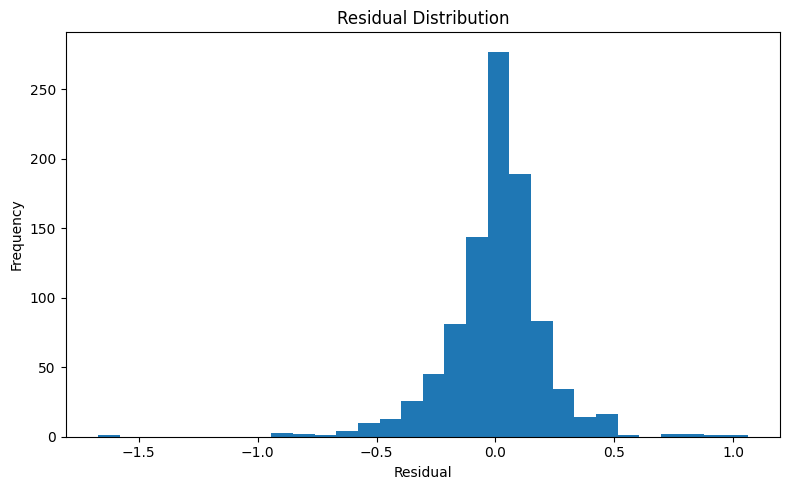

In [170]:
plt.figure(figsize=(8, 5))

plt.hist(
    residuals,
    bins=30
)

plt.title("Residual Distribution")
plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## Residual ACF

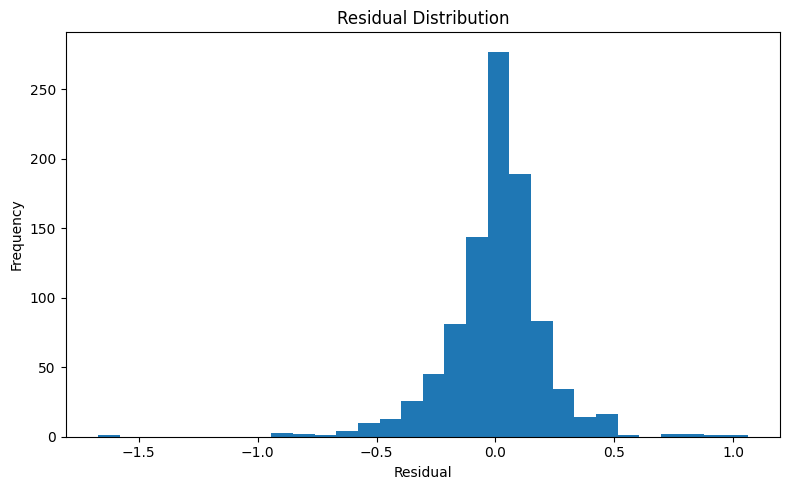

In [171]:
plt.figure(figsize=(8, 5))

plt.hist(
    residuals,
    bins=30
)

plt.title("Residual Distribution")
plt.xlabel("Residual")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## Ljung-Box test

In [173]:
ljung_box = acorr_ljungbox(
    residuals.dropna(),
    lags=[10],
    return_df=True
)

print(ljung_box)

      lb_stat  lb_pvalue
10  15.864467   0.103578


In [174]:
lb_pvalue = ljung_box["lb_pvalue"].iloc[0]

print("Ljung-Box p-value:", lb_pvalue)

if lb_pvalue > 0.05:
    print(
        "Residuals appear to be white noise."
    )
else:
    print(
        "Residual autocorrelation remains."
    )

Ljung-Box p-value: 0.10357847140049109
Residuals appear to be white noise.


## Forecasting future NAV

In [177]:
FUTURE_HORIZON = 30

print("=" * 70)
print("STEP 39: FUTURE NAV FORECAST USING HOLT'S MODEL")
print("=" * 70)

print(f"Forecast horizon: {FUTURE_HORIZON} trading days")
print(f"Last available NAV date: {ts.index.max().date()}")

STEP 39: FUTURE NAV FORECAST USING HOLT'S MODEL
Forecast horizon: 30 trading days
Last available NAV date: 2026-08-26


### Creating future business dates

In [181]:
future_index = pd.bdate_range(
    start=ts.index.max() + pd.Timedelta(days=1),
    periods=FUTURE_HORIZON
)

print("\nFuture forecast dates:")
print(future_index[0].date())
print("to")
print(future_index[-1].date())


Future forecast dates:
2026-08-27
to
2026-10-07


## Fitting Holt's Model on Full dataset

In [183]:
final_holt_model = ExponentialSmoothing(
    ts,
    trend="add",
    seasonal=None,
    initialization_method="estimated"
)

final_holt_fit = final_holt_model.fit()

print("Holt's model fitted on the full dataset.")

Holt's model fitted on the full dataset.


### Checking the parameters

In [184]:
print("\nEstimated Holt parameters:")
print("--------------------------------")

print(
    "Smoothing level (alpha):",
    final_holt_fit.params["smoothing_level"]
)

print(
    "Smoothing trend (beta):",
    final_holt_fit.params["smoothing_trend"]
)

print(
    "Initial level:",
    final_holt_fit.params["initial_level"]
)

print(
    "Initial trend:",
    final_holt_fit.params["initial_trend"]
)


Estimated Holt parameters:
--------------------------------
Smoothing level (alpha): 0.9999999850988388
Smoothing trend (beta): 0.0
Initial level: 19.527977372285065
Initial trend: 0.012021172720392811


## Generating 30 day forecast

In [185]:
future_fc = final_holt_fit.forecast(
    FUTURE_HORIZON
)

future_fc.index = future_index

print("\nFuture NAV forecast:")
print(future_fc)


Future NAV forecast:
2026-08-27    32.042021
2026-08-28    32.054042
2026-08-31    32.066064
2026-09-01    32.078085
2026-09-02    32.090106
2026-09-03    32.102127
2026-09-04    32.114148
2026-09-07    32.126169
2026-09-08    32.138191
2026-09-09    32.150212
2026-09-10    32.162233
2026-09-11    32.174254
2026-09-14    32.186275
2026-09-15    32.198296
2026-09-16    32.210318
2026-09-17    32.222339
2026-09-18    32.234360
2026-09-21    32.246381
2026-09-22    32.258402
2026-09-23    32.270423
2026-09-24    32.282445
2026-09-25    32.294466
2026-09-28    32.306487
2026-09-29    32.318508
2026-09-30    32.330529
2026-10-01    32.342550
2026-10-02    32.354572
2026-10-05    32.366593
2026-10-06    32.378614
2026-10-07    32.390635
Freq: B, dtype: float64


In [186]:
future_table = pd.DataFrame({
    "Date": future_index,
    "Forecast NAV": np.round(
        future_fc.values,
        2
    )
})

print("\n" + "=" * 70)
print("30-DAY FUTURE NAV FORECAST")
print("=" * 70)

print(
    future_table.to_string(index=False)
)


30-DAY FUTURE NAV FORECAST
      Date  Forecast NAV
2026-08-27         32.04
2026-08-28         32.05
2026-08-31         32.07
2026-09-01         32.08
2026-09-02         32.09
2026-09-03         32.10
2026-09-04         32.11
2026-09-07         32.13
2026-09-08         32.14
2026-09-09         32.15
2026-09-10         32.16
2026-09-11         32.17
2026-09-14         32.19
2026-09-15         32.20
2026-09-16         32.21
2026-09-17         32.22
2026-09-18         32.23
2026-09-21         32.25
2026-09-22         32.26
2026-09-23         32.27
2026-09-24         32.28
2026-09-25         32.29
2026-09-28         32.31
2026-09-29         32.32
2026-09-30         32.33
2026-10-01         32.34
2026-10-02         32.35
2026-10-05         32.37
2026-10-06         32.38
2026-10-07         32.39


## Expected NAV Change

In [187]:
last_actual = ts.iloc[-1]

last_forecast = future_fc.iloc[-1]

absolute_change = last_forecast - last_actual

percentage_change = (
    absolute_change / last_actual
) * 100

print("\n" + "=" * 70)
print("FORECAST SUMMARY")
print("=" * 70)

print(
    f"Last actual NAV     : ₹{last_actual:.2f}"
)

print(
    f"30-day forecast NAV : ₹{last_forecast:.2f}"
)

print(
    f"Expected change     : ₹{absolute_change:.2f}"
)

print(
    f"Expected % change   : {percentage_change:+.2f}%"
)


FORECAST SUMMARY
Last actual NAV     : ₹32.03
30-day forecast NAV : ₹32.39
Expected change     : ₹0.36
Expected % change   : +1.13%


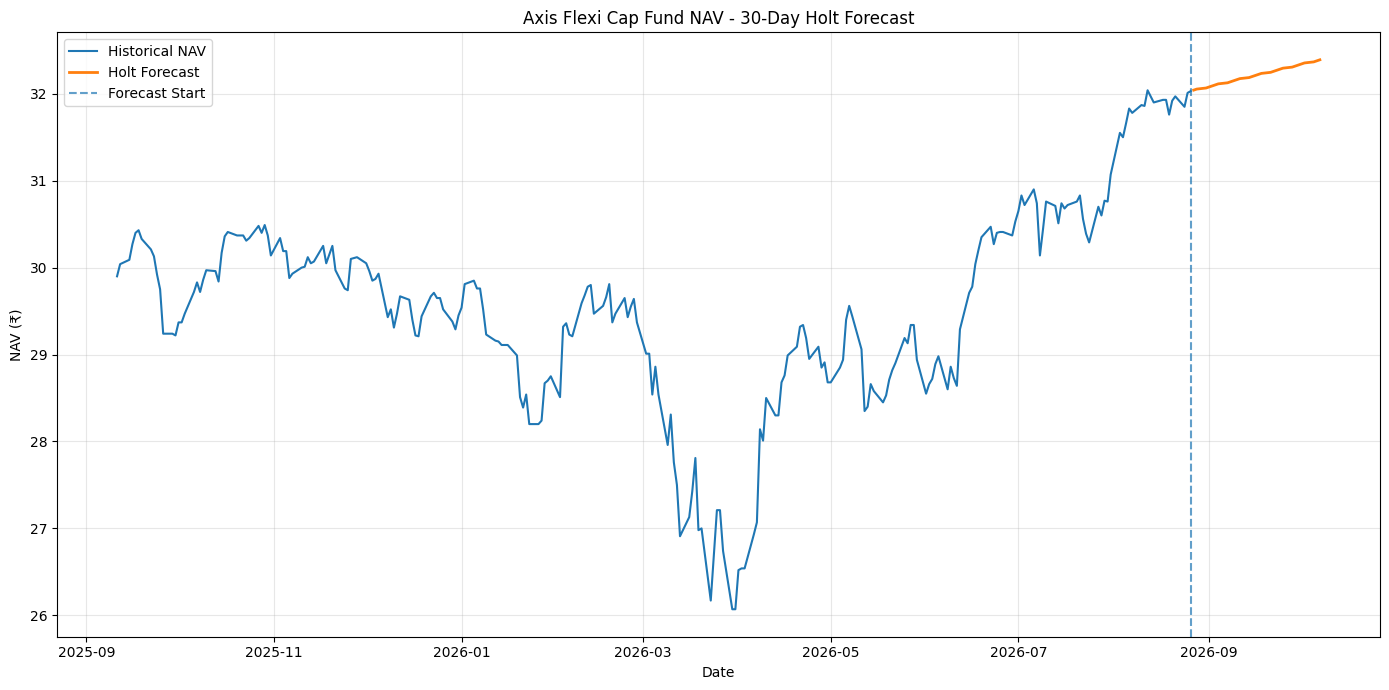

In [188]:
plt.figure(figsize=(14, 7))

# Recent historical NAV
plt.plot(
    ts.index[-250:],
    ts.values[-250:],
    label="Historical NAV"
)

# Future forecast
plt.plot(
    future_fc.index,
    future_fc.values,
    label="Holt Forecast",
    linewidth=2
)

# Mark the point where forecasting begins
plt.axvline(
    ts.index.max(),
    linestyle="--",
    alpha=0.7,
    label="Forecast Start"
)

plt.title(
    "Axis Flexi Cap Fund NAV - 30-Day Holt Forecast"
)

plt.xlabel("Date")
plt.ylabel("NAV (₹)")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()